## **Stochastic Process (SP)**

**Random Variable:**

Mathematically, it is a function $f: \Omega \to R$. but what does it mean?

*Think of a **random machine** or an activity which gives you *8numerical real number**.*

It is simple. we can find this in many activities in our real life. for example: 
- Tossing a coin
- Rolling a dice
- The height of a man.
- The number of people who click an ad today.
- The number of complaints received by a tech platform on a Tuesday.
- The number of patients entering an ER tonight.
- The number of cups a cafe sells in the morning.
- The exact percentage money gain or loss on a stock.
- The minutes it takes a driver to bring your food.
- The total inches of rain during a storm.
- The weight in grams of a single piece of fruit.
- The exact download speed of your Wi-Fi right now.

These all provides a numerical value randomly. 

`Note: the concept of discrete and continuous varibale is easy.`


**Think: how to generate a random number in Python?**

In [ ]:
# this generates one random number from the standard normal distribution.
import numpy as np

rng = np.random.default_rng(seed=0)

x = rng.normal(0, 1)
print(x)

0.1257302210933933


### **Stochastic Process**

**Mathematical definition**

A stochastic process is a collection of random variables indexed by time:
$$
\{X_t:t\in[0,T]\}
$$

Here:
- $t$ is time.
- $X_t$ is a random variable representing the quantity at time $t$.
- $T$ is the end of the time interval.

For example, suppose we observe a process at times $t=0,1,2,3,4$:
$$
X_0,\ X_1,\ X_2,\ X_3,\ X_4.
$$

Each $X_t$ is random. One simulation produces one possible sequence of values.

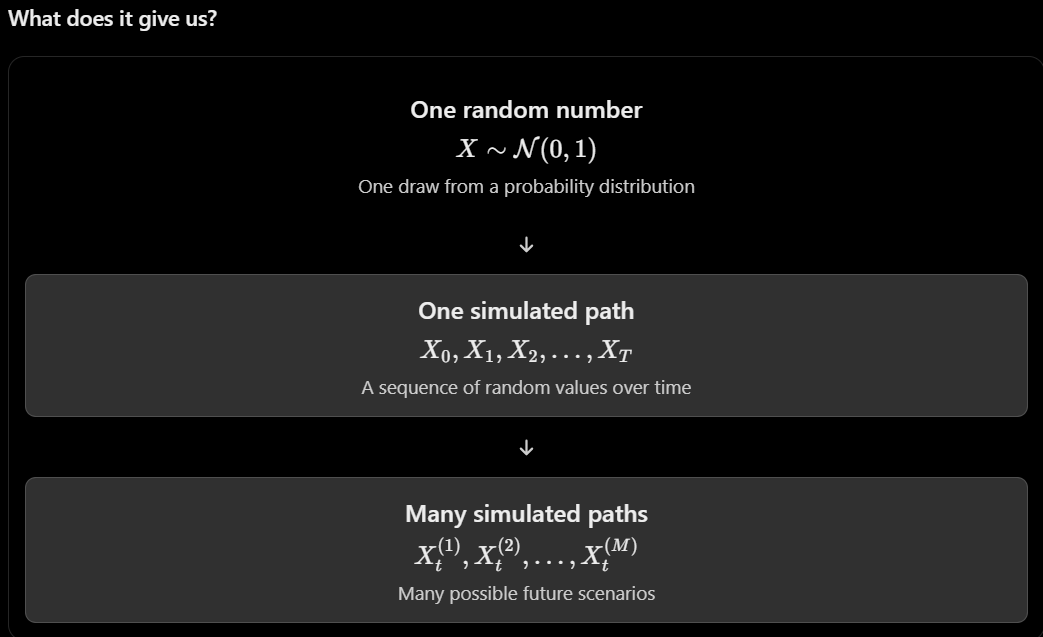

A **path** is one realization of the process. If we simulate the same process 1,000 times, we obtain 1,000 possible paths.

**Why we use Stochastic Process?**

Suppose in a real life situation if we want to simulate how a quantity changes over time, rather than generate only one number?

Examples:
- A stock price changing every second.
- A portfolio's cumulative loss changing every day.
- The number of customers arriving at a bank.
- The temperature changing throughout a day.

For these problems, we use a stochastic process.

### **1. Standard Brownian Motion**

Brownian motion is one of the most important **stochastic processes** in probability, physics, and mathematical finance.

**Mathematical definition**

A **standard Brownian motion**, also called a standard **Wiener process**, is a process $\{W_t:t\geq0\}$ satisfying:
1. $W_0=0$.
2. It has independent increments.
3. For $0\leq s<t$,
   $$
   W_t-W_s\sim\mathcal N(0,t-s).
   $$
4. Its paths are continuous with probability one.

Simply, think like a random machine gives random values on every time $t$. its starting value as 0, without any pattern (the previous generated random numbers can not be same in the future time), follows the normal distribution, and no jumps or discontinuity.


*In **finance**, it can model random fluctuations in an asset-price model. It is not itself a stock price: it is a random component used to construct a model.*


**What does it generate?**

It generates a random path over time.

#### **How to simulate the SBM?**

To simulate it, divide the time interval into small steps of length $\Delta t$. Then generate
$$
\Delta W_k\sim\mathcal N(0,\Delta t)
$$

and update the process:
$$
W_{t_k}=W_{t_{k-1}}+\Delta W_k.
$$

Since a normal random variable with variance $\Delta t$ can be generated as $\sqrt{\Delta t}Z_k$, where $Z_k\sim\mathcal N(0,1)$, we use
$$
\boxed{W_{t_k}=W_{t_{k-1}}+\sqrt{\Delta t}\,Z_k.}
$$

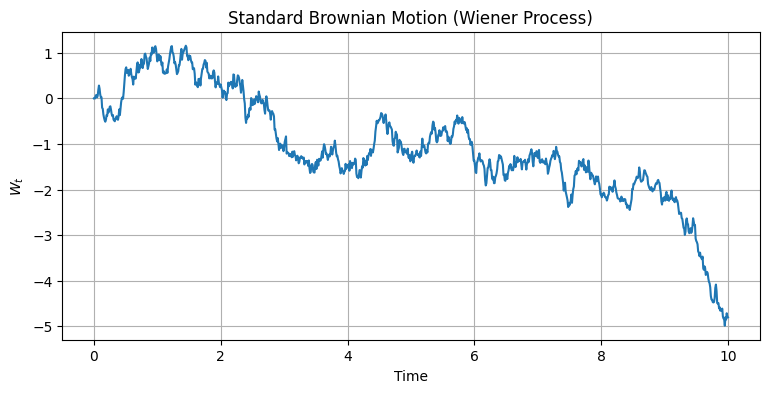

In [9]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)

# Time parameters
T = 10
N = 1000
dt = T / N
t = np.linspace(0, T, N + 1)

# Simulate standard Brownian motion
dW = np.sqrt(dt) * rng.normal(0, 1, N)
W = np.zeros(N + 1)
W[1:] = np.cumsum(dW)

# Plot the path
plt.figure(figsize=(9, 4))
plt.plot(t, W)
plt.xlabel("Time")
plt.ylabel(r"$W_t$")
plt.title("Standard Brownian Motion (Wiener Process)")
plt.grid(True)
plt.show()

### **2. Geometric Brownian Motion GBM**



### **3. Gaussian Process**

**Mathematical definition**

A process $\{G_t\}$ is a Gaussian process if, for every finite collection of times $t_1,\ldots,t_n$, the random vector
$$
(G_{t_1},G_{t_2},\ldots,G_{t_n})
$$

has a multivariate Gaussian distribution.
A Gaussian process is commonly specified by its mean function and covariance function:
$$
m(t)=\mathbb E[G_t],
$$

$$
K(s,t)=\operatorname{Cov}(G_s,G_t).
$$

The covariance function tells us how values at different times are related.

Suppose we model the temperature throughout a day. Temperatures at nearby times tend to be similar: a temperature at 10:01 is usually more closely related to the temperature at 10:00 than to the temperature at midnight.

A Gaussian process can model such smooth, correlated random functions.

Gaussian processes are also used in regression and machine learning to model uncertain functions.

***Brownian motion** is a particular kind of Gaussian process, but not every Gaussian process is Brownian motion.*

#### **How to simulate GP?**

The following example generates one Gaussian-process sample using a squared-exponential (RBF) covariance function:
$$
K(s,t)=\exp\left(-\frac{(s-t)^2}{2\ell^2}\right),
$$

where $\ell$ controls how quickly the correlation decreases with distance in time.

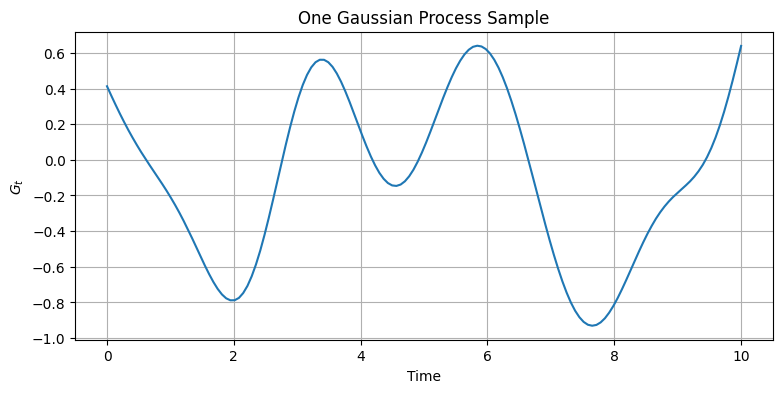

In [10]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)

t = np.linspace(0, 10, 150)
ell = 1.0

# Construct the covariance matrix
K = np.exp(-0.5 * ((t[:, None] - t[None, :]) / ell)**2)

# Small diagonal term for numerical stability
K += 1e-8 * np.eye(len(t))

# Generate one Gaussian process sample
G = rng.multivariate_normal(np.zeros(len(t)), K)

plt.figure(figsize=(9, 4))
plt.plot(t, G)
plt.xlabel("Time")
plt.ylabel(r"$G_t$")
plt.title("One Gaussian Process Sample")
plt.grid(True)
plt.show()

### **4.Poisson process**

Brownian motion models continuous random fluctuations. But what if we want to model random events that happen at particular times?

Examples include customer arrivals, insurance claims, or jump arrivals in a financial model.

**Mathematical definition**

A Poisson process $\{N_t:t\geq0\}$ with rate $\lambda>0$ satisfies:
1. $N_0=0$.
2. It counts events, so it is nondecreasing and integer-valued.
3. It has independent increments.
4. The number of events during an interval of length $t$ follows a Poisson distribution:
   $$
   \boxed{N_t\sim\operatorname{Poisson}(\lambda t).}
   $$

In particular,
$$
P(N_t=n)=\frac{(\lambda t)^n e^{-\lambda t}}{n!},
\qquad n=0,1,2,\ldots
$$

Here, $\lambda$ is the average number of events per unit of time.


**Idea:**

Suppose customers arrive at a service desk at an average rate of 3 customers per hour.
Then $\lambda=3$, and the number of arrivals in one hour follows
$$
N_1\sim\operatorname{Poisson}(3).
$$

The process tells us how many events have occurred by each time. It does not tell us the size or financial impact of each event.

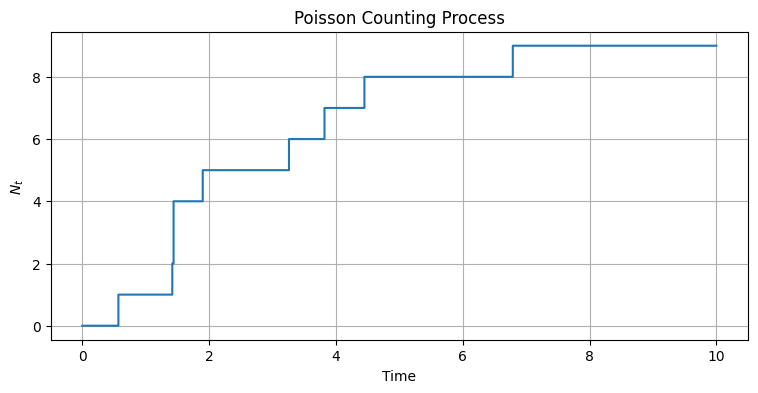

Total number of events: 9


In [11]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)

# Time parameters
T = 10
N = 1000
t = np.linspace(0, T, N + 1)

# Average number of events per unit time
lam = 1.2

# Generate event times using exponential waiting times
event_times = []
current_time = 0.0

while True:
    current_time += rng.exponential(scale=1 / lam)

    if current_time > T:
        break

    event_times.append(current_time)

# Count the number of events up to each time
Nt = np.searchsorted(event_times, t, side="right")

plt.figure(figsize=(9, 4))
plt.step(t, Nt, where="post")
plt.xlabel("Time")
plt.ylabel(r"$N_t$")
plt.title("Poisson Counting Process")
plt.grid(True)
plt.show()

print("Total number of events:", len(event_times))

### **5. Jump process**

A jump process is a stochastic process that can change suddenly at random times. Some jump processes also have continuous movement between jumps.

A Poisson process is one example of a jump process. A compound Poisson process is another.
Mathematical definition

A simple compound Poisson process is defined as
$$
\boxed{J_t=\sum_{i=1}^{N_t}Y_i,}
$$

where:
- $N_t$ is a Poisson process that counts the jumps.
- $Y_i$ is the size of the $i$-th jump.
- $J_t$ is the cumulative sum of the jump sizes.
- If no jumps have occurred, the sum is zero.

Unlike a Poisson counting process, $J_t$ does not have to increase. Its jump sizes may be positive or negative.

**Idea:**

Imagine an insurance company whose cumulative claims change whenever a claim arrives.
- The arrival time determines when the jump happens.
- The claim amount determines how large the jump is.
- The cumulative process adds all the claims received so far.
In financial modeling, jumps can represent sudden market movements or unexpected changes in losses.

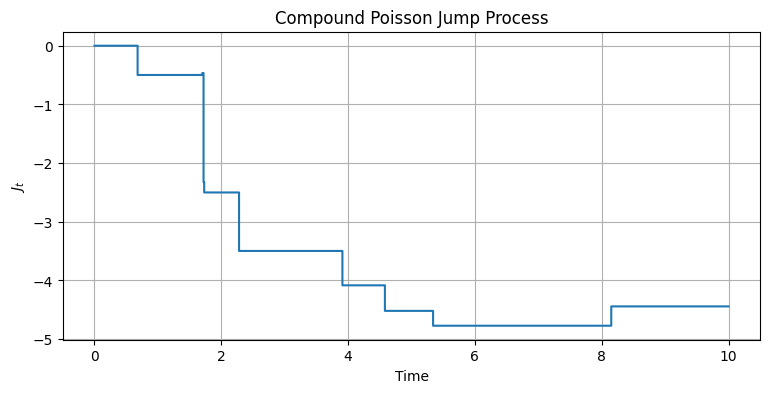

In [12]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)

T = 10
lam = 1.0

# Generate random jump times
event_times = []
current_time = 0.0

while True:
    current_time += rng.exponential(scale=1 / lam)

    if current_time > T:
        break

    event_times.append(current_time)

# Generate jump sizes
jump_sizes = rng.normal(0, 0.8, size=len(event_times))

# Create a time grid
t = np.linspace(0, T, 1001)
J = np.zeros(len(t))

# Accumulate the jumps
for event_time, jump_size in zip(event_times, jump_sizes):
    J[t >= event_time] += jump_size

plt.figure(figsize=(9, 4))
plt.step(t, J, where="post")
plt.xlabel("Time")
plt.ylabel(r"$J_t$")
plt.title("Compound Poisson Jump Process")
plt.grid(True)
plt.show()

### **6. Lévy process**

**Mathematical definition**

A Lévy process $\{X_t:t\geq0\}$ is a stochastic process satisfying:
1. $X_0=0$ almost surely.
2. It has independent increments.
3. It has stationary increments: the distribution of $X_{t+s}-X_s$ depends only on $t$.
4. It is continuous in probability.
5. It has paths that are right-continuous and have left limits.

The last property allows sudden jumps.

`Important: not every Lévy process has jumps. Brownian motion is also a Lévy process.`

**Examples include:**
- Brownian motion.
- A Poisson process.
- A compound Poisson process.
- A Brownian motion combined with a jump process.

A Lévy process provides a flexible way to model cumulative changes over time. It can include both small continuous fluctuations and sudden jumps.

This is useful in financial modeling because asset returns and portfolio losses may experience both ordinary fluctuations and sudden movements.

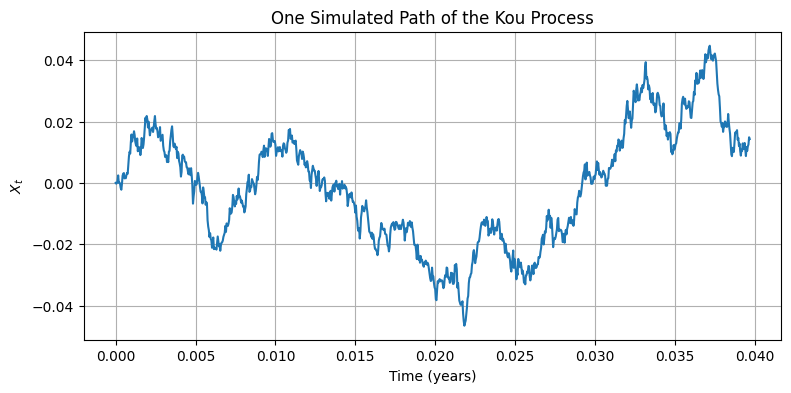

In [13]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)

# Kou model parameters
T = 10 / 252
N = 1000
dt = T / N

lam = 3.0
P = 0.6
Lp = 15.0
Lm = 10.0
sigma = 0.3
gam0 = 0.2

# Initialize the process
X = np.zeros(N + 1)
t = np.linspace(0, T, N + 1)

for k in range(1, N + 1):

    # Generate the number of jumps during this time step
    j = rng.poisson(lam * dt)

    # Simulate and accumulate the jumps
    for i in range(j):
        U = rng.uniform(0, 1)

        if U < P:
            Y = rng.exponential(scale=1 / Lp)
        else:
            Y = -rng.exponential(scale=1 / Lm)

        X[k] = X[k] + Y

    # Add the drift and Brownian increment
    X[k] += gam0 * dt + sigma * np.sqrt(dt) * rng.normal()

    # Accumulate the previous process value
    X[k] += X[k - 1]

plt.figure(figsize=(9, 4))
plt.plot(t, X)
plt.xlabel("Time (years)")
plt.ylabel(r"$X_t$")
plt.title("One Simulated Path of the Kou Process")
plt.grid(True)
plt.show()